import all libraries

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

Part A

1- Load and Inspect

In [18]:
# Load the original CSV file
df = pd.read_csv("sales_raw.csv")

# Display first five rows
print("First five rows:")
print(df.head())

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns)

# Display data types
print("\nData Types:")
print(df.dtypes)

# Check missing values in each column
print("Missing Values:")
print(df.isna().sum())

# Check duplicate rows
print("\nDuplicate Rows:")
print(df.duplicated().sum())

First five rows:
   transaction_id  sale_date region    category  quantity unit_price
0            1001  10/1/2026  North       food        2.0        120
1            1002  10/1/2026  South       Books       1.0        250
2            1003  10/2/2026  North        Food       3.0        110
3            1004  10/2/2026   East  Stationery       4.0         50
4            1005  10/3/2026  SOUTH       books       2.0        250

Dataset Shape:
(21, 6)

Column Names:
Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price'],
      dtype='object')

Data Types:
transaction_id      int64
sale_date          object
region             object
category           object
quantity          float64
unit_price         object
dtype: object
Missing Values:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Duplicate Rows:
1


2- Clean dataset

In [19]:
# Preserve original dataset
cleaned_df = df.copy()

# Store original row count
original_rows = len(cleaned_df)

print("Original row count:", original_rows)

# Clean region column
cleaned_df["region"] = (
    cleaned_df["region"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Clean category column
cleaned_df["category"] = (
    cleaned_df["category"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Display cleaned text columns
print(cleaned_df[["region", "category"]].head())
# Check missing values before handling
print("Missing values before cleaning:")
print(cleaned_df.isna().sum())

# Remove rows where essential information is missing
cleaned_df = cleaned_df.dropna(
    subset=["region", "category", "quantity", "unit_price"]
)

print("\nMissing values after cleaning:")
print(cleaned_df.isna().sum())

# Convert quantity and unit_price into numeric values
cleaned_df["quantity"] = pd.to_numeric(
    cleaned_df["quantity"], errors="coerce"
)

cleaned_df["unit_price"] = pd.to_numeric(
    cleaned_df["unit_price"], errors="coerce"
)

# Remove missing or invalid numeric values
cleaned_df = cleaned_df.dropna(
    subset=["quantity", "unit_price"]
)

# Remove negative or zero prices
cleaned_df = cleaned_df[cleaned_df["unit_price"] > 0]

# Remove invalid quantities
cleaned_df = cleaned_df[cleaned_df["quantity"] > 0]

print("Invalid prices and quantities removed.")

# Store final row count
cleaned_rows = len(cleaned_df)

# Calculate removed rows
removed_rows = original_rows - cleaned_rows

print("Original Rows:", original_rows)
print("Rows After Cleaning:", cleaned_rows)
print("Rows Removed:", removed_rows)

Original row count: 21
  region    category
0  North        Food
1  South       Books
2  North        Food
3   East  Stationery
4  South       Books
Missing values before cleaning:
transaction_id    0
sale_date         0
region            1
category          0
quantity          1
unit_price        1
dtype: int64

Missing values after cleaning:
transaction_id    0
sale_date         0
region            0
category          0
quantity          0
unit_price        0
dtype: int64
Invalid prices and quantities removed.
Original Rows: 21
Rows After Cleaning: 16
Rows Removed: 5


3- Calculate and analyze

In [20]:
# Calculate revenue
cleaned_df["revenue"] = (
    cleaned_df["quantity"] * cleaned_df["unit_price"]
)

# Display updated dataset
print(cleaned_df.head())

# Group revenue by region
region_summary = cleaned_df.groupby("region")["revenue"].sum()

# Display summary
print("Revenue by Region:")
print(region_summary)

# Group revenue by category
category_summary = cleaned_df.groupby("category")["revenue"].sum()

# Display summary
print("\nRevenue by Category:")
print(category_summary)

   transaction_id  sale_date region    category  quantity  unit_price  revenue
0            1001  10/1/2026  North        Food       2.0       120.0    240.0
1            1002  10/1/2026  South       Books       1.0       250.0    250.0
2            1003  10/2/2026  North        Food       3.0       110.0    330.0
3            1004  10/2/2026   East  Stationery       4.0        50.0    200.0
4            1005  10/3/2026  South       Books       2.0       250.0    500.0
Revenue by Region:
region
East       740.0
North    11800.0
South     1035.0
West      1130.0
Name: revenue, dtype: float64

Revenue by Category:
category
Books          1970.0
Food           2275.0
Stationery    10460.0
Name: revenue, dtype: float64


Revenue by Region

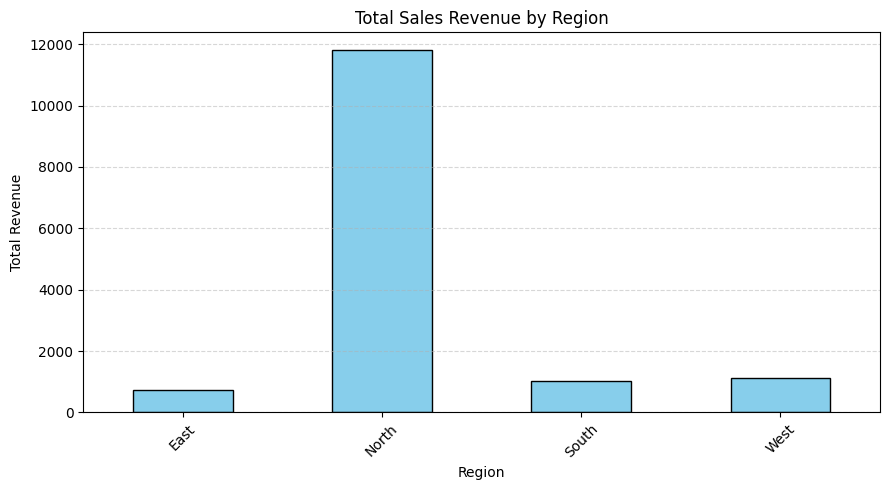

In [21]:
plt.figure(figsize=(9, 5))

region_summary.plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Total Sales Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("revenue_by_region.png")
plt.show()

Revenue by Category

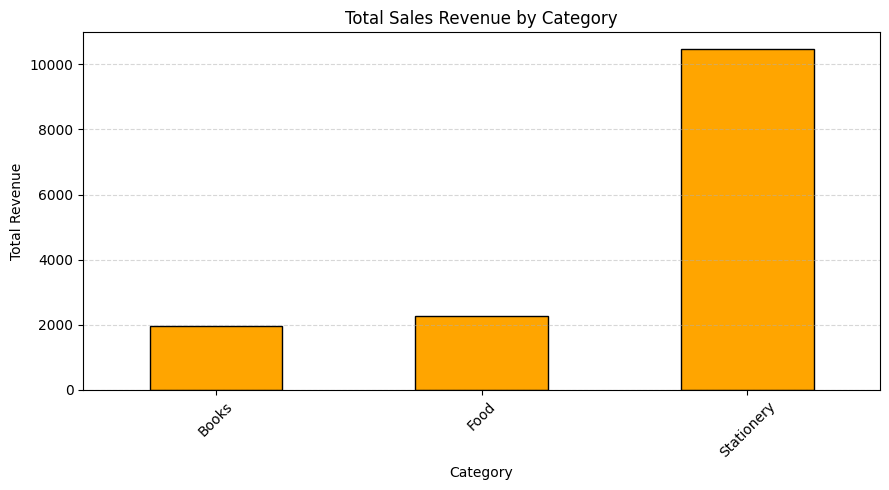

In [22]:
plt.figure(figsize=(9, 5))

category_summary.plot(
    kind="bar",
    color="orange",
    edgecolor="black"
)

plt.title("Total Sales Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("revenue_by_category.png")
plt.show()

two evidence-based findings

In [23]:
# Find region with highest revenue
best_region = region_summary.idxmax()
highest_region_revenue = region_summary.max()

# Find category with highest revenue
best_category = category_summary.idxmax()
highest_category_revenue = category_summary.max()

print("FINDING 1:")
print(
    f"The {best_region} region generated the highest revenue "
    f"of {highest_region_revenue:.2f}."
)

print("\nFINDING 2:")
print(
    f"The {best_category} category generated the highest revenue "
    f"of {highest_category_revenue:.2f}."
)

FINDING 1:
The North region generated the highest revenue of 11800.00.

FINDING 2:
The Stationery category generated the highest revenue of 10460.00.


4- Save the cleaned dataset

In [24]:
# Export cleaned dataset
cleaned_df.to_csv("cleaned_sales.csv", index=False)

print("Cleaned dataset successfully saved as cleaned_sales.csv")

Cleaned dataset successfully saved as cleaned_sales.csv


Part B

1- Read and add a column

In [26]:
# Load cleaned dataset
df = pd.read_csv("cleaned_sales.csv")

# Display first five rows
print("First Five Rows:")
print(df.head())

# Display dataset information
print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns)

# Add tax amount column
df["tax_amount"] = df["revenue"] * 0.05

# Display first five rows
print("First Five Rows After Adding Tax:")
print(df.head())

First Five Rows:
   transaction_id  sale_date region    category  quantity  unit_price  revenue
0            1001  10/1/2026  North        Food       2.0       120.0    240.0
1            1002  10/1/2026  South       Books       1.0       250.0    250.0
2            1003  10/2/2026  North        Food       3.0       110.0    330.0
3            1004  10/2/2026   East  Stationery       4.0        50.0    200.0
4            1005  10/3/2026  South       Books       2.0       250.0    500.0

Dataset Shape:
(16, 7)

Column Names:
Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price', 'revenue'],
      dtype='object')
First Five Rows After Adding Tax:
   transaction_id  sale_date region    category  quantity  unit_price  \
0            1001  10/1/2026  North        Food       2.0       120.0   
1            1002  10/1/2026  South       Books       1.0       250.0   
2            1003  10/2/2026  North        Food       3.0       110.0   
3            1004

2- Update and remove

In [29]:
# Increase Books unit_price by 10%
df.loc[df["category"] == "Books", "unit_price"] *= 1.10

# Recalculate revenue after price increase
df["revenue"] = df["quantity"] * df["unit_price"]

# Recalculate tax amount
df["tax_amount"] = df["revenue"] * 0.05

# Display updated Books records
print("Updated Books Records:")
print(df.loc[df["category"] == "Books"].head())

# Display available transaction IDs
print("Available Transaction IDs:")
print(df["transaction_id"].head(10))

# Select an existing transaction ID
selected_id = df["transaction_id"].iloc[0]

# Remove the selected transaction
df = df.loc[df["transaction_id"] != selected_id].copy()

print("Removed Transaction ID:", selected_id)

# Display updated dataset
print(df.head())

Updated Books Records:
   transaction_id     sale_date region category  quantity  unit_price  \
1            1002     10/1/2026  South    Books       1.0      332.75   
4            1005     10/3/2026  South    Books       2.0      332.75   
6            1008     10/4/2026   East    Books       1.0      399.30   
8            1012     10/6/2026  North    Books       1.0      425.92   
9            1014  invalid-date   West    Books       2.0      399.30   

   revenue  tax_amount  
1   332.75     16.6375  
4   665.50     33.2750  
6   399.30     19.9650  
8   425.92     21.2960  
9   798.60     39.9300  
Available Transaction IDs:
0    1001
1    1002
2    1003
3    1004
4    1005
5    1007
6    1008
7    1009
8    1012
9    1014
Name: transaction_id, dtype: int64
Removed Transaction ID: 1001
   transaction_id  sale_date region    category  quantity  unit_price  \
1            1002  10/1/2026  South       Books       1.0      332.75   
2            1003  10/2/2026  North        Food    

Create a temporary review_status column

In [31]:
# Create temporary review_status column
df["review_status"] = "Reviewed"

# Display first five rows
print("Dataset With Temporary Column:")
print(df.head())

# Remove temporary review_status column
df = df.drop(columns=["review_status"])

# Display remaining columns
print("Columns After Removing Temporary Column:")
print(df.columns)

Dataset With Temporary Column:
   transaction_id  sale_date region    category  quantity  unit_price  \
1            1002  10/1/2026  South       Books       1.0      332.75   
2            1003  10/2/2026  North        Food       3.0      110.00   
3            1004  10/2/2026   East  Stationery       4.0       50.00   
4            1005  10/3/2026  South       Books       2.0      332.75   
5            1007  10/4/2026  North  Stationery       3.0       60.00   

   revenue  tax_amount review_status  
1   332.75     16.6375      Reviewed  
2   330.00     16.5000      Reviewed  
3   200.00     10.0000      Reviewed  
4   665.50     33.2750      Reviewed  
5   180.00      9.0000      Reviewed  
Columns After Removing Temporary Column:
Index(['transaction_id', 'sale_date', 'region', 'category', 'quantity',
       'unit_price', 'revenue', 'tax_amount'],
      dtype='object')


3- Save and verify

In [34]:
# Save updated dataset
df.to_csv("sales_updated.csv", index=False)

print("Updated dataset successfully saved as sales_updated.csv")

# Read the updated CSV file
updated_df = pd.read_csv("sales_updated.csv")

# Display first five rows
print("First Five Rows of Updated CSV:")
print(updated_df.head())

# Display final column names
print("\nFinal Column Names:")
print(updated_df.columns.tolist())

# Display final dataset shape
print("\nFinal Dataset Shape:")
print(updated_df.shape)

Updated dataset successfully saved as sales_updated.csv
First Five Rows of Updated CSV:
   transaction_id  sale_date region    category  quantity  unit_price  \
0            1002  10/1/2026  South       Books       1.0      332.75   
1            1003  10/2/2026  North        Food       3.0      110.00   
2            1004  10/2/2026   East  Stationery       4.0       50.00   
3            1005  10/3/2026  South       Books       2.0      332.75   
4            1007  10/4/2026  North  Stationery       3.0       60.00   

   revenue  tax_amount  
0   332.75     16.6375  
1   330.00     16.5000  
2   200.00     10.0000  
3   665.50     33.2750  
4   180.00      9.0000  

Final Column Names:
['transaction_id', 'sale_date', 'region', 'category', 'quantity', 'unit_price', 'revenue', 'tax_amount']

Final Dataset Shape:
(15, 8)
